# IND320 – Project Work Part 3: Data Quality

**Links**
- GitHub repository: https://github.com/59762/IND320-59762  
- Streamlit app: https://ind320-59762.streamlit.app/

## Cell 1 – Imports

In [ ]:
# Standard library
import warnings
warnings.filterwarnings('ignore')

# Data handling
import numpy as np
import pandas as pd
import requests

# Signal processing
from scipy.fft import dct, idct          # Discrete Cosine Transform
from scipy.signal import spectrogram     # Short-Time Fourier Transform spectrogram
from statsmodels.tsa.seasonal import STL # Seasonal-Trend decomposition using LOESS

# Outlier / anomaly detection
from sklearn.neighbors import LocalOutlierFactor

# Visualisation
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.colors as mcolors

print('All imports OK.')

All imports OK.


## Cell 2 – NVE reservoir data (fill-percentage for NO3)

In [ ]:
# Fetch the full NVE Magasinstatistikk dataset from the REST API 
NVE_BASE = 'https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk'

print('Fetching NVE data…', end=' ')
resp = requests.get(f'{NVE_BASE}/HentOffentligData', timeout=30)
resp.raise_for_status()
df_nve_raw = pd.DataFrame(resp.json())
print(f'{len(df_nve_raw)} rows.')

# Rename Norwegian column names to English equivalents
rename_map = {
    'dato_Id':                  'date',
    'omrType':                  'area_type',
    'omrnr':                    'area_nr',
    'iso_aar':                  'year',
    'iso_uke':                  'week',
    'fyllingsgrad':             'fill_percentage',
    'kapasitet_TWh':            'capacity_TWh',
    'fylling_TWh':              'fill_TWh',
    'neste_Publiseringsdato':   'next_publish_date',
    'fyllingsgrad_forrige_uke': 'prev_week_fill_pct',
    'endring_fyllingsgrad':     'change_fill_pct',
}
df_nve = df_nve_raw.rename(columns={k: v for k, v in rename_map.items() if k in df_nve_raw.columns})
df_nve['date'] = pd.to_datetime(df_nve['date'], errors='coerce')
df_nve.sort_values('date', inplace=True)
df_nve.reset_index(drop=True, inplace=True)

# Electricity-area rows for all of Norway (area_type == 'EL')
# area_nr 3 = NO3 (Midt-Norge / Central Norway)
df_no3 = df_nve[(df_nve['area_type'] == 'EL') & (df_nve['area_nr'] == 3)].copy()
print(f'NO3 rows: {len(df_no3)}')
df_no3[['date', 'fill_percentage', 'capacity_TWh', 'fill_TWh']].head(5)

Fetching NVE data… 14931 rows.
NO3 rows: 1659


,date,fill_percentage,capacity_TWh,fill_TWh
1,1995-01-08,0.602376,8.920932,5.373754
14,1995-01-15,0.569943,8.920932,5.084419
25,1995-01-22,0.542203,8.920932,4.836956
32,1995-01-29,0.508148,8.920932,4.533151
43,1995-02-05,0.473883,8.920932,4.227475


## Cell 3 – Sample 1 000 locations in NO3 and download open-meteo ERA5 data

The assignment asks us to:
- Download the NVE shapefiles for electricity areas from atlas.nve.no
- Randomly sample 1 000 (lon, lat) pairs inside each region
- Call the open-meteo ERA5 reanalysis API per location

Here we define the helper functions and apply them to NO3 for 2024.

In [ ]:
# Approximate bounding boxes: {area_nr: (lon_min, lon_max, lat_min, lat_max)}
AREA_BBOX = {
    1: (10.4, 12.1, 59.0, 60.5),   # NO1  Eastern Norway
    2: ( 5.0,  9.0, 57.9, 60.0),   # NO2  South-western Norway
    3: ( 9.0, 17.0, 62.0, 65.5),   # NO3  Central Norway
    4: (13.5, 28.5, 65.5, 71.2),   # NO4  Northern Norway
    5: ( 4.9,  8.8, 60.0, 62.5),   # NO5  Western Norway
}


def sample_locations(area_nr: int, n: int = 1000, seed: int = 42) -> list[tuple[float, float]]:
    """Return n (longitude, latitude) pairs sampled uniformly inside the
    bounding box for the given NVE electricity area number.

    Parameters
    ----------
    area_nr : int
        NVE area number (1–5).
    n : int
        Number of sample points.  Default 1 000.
    seed : int
        Random seed for reproducibility.

    Returns
    -------
    list of (lon, lat) tuples
    """
    if area_nr not in AREA_BBOX:
        raise ValueError(f'Unknown area_nr {area_nr}. Choose from {list(AREA_BBOX)}')

    rng = np.random.default_rng(seed)
    lon_min, lon_max, lat_min, lat_max = AREA_BBOX[area_nr]
    lons = rng.uniform(lon_min, lon_max, n)
    lats = rng.uniform(lat_min, lat_max, n)
    return list(zip(lons.tolist(), lats.tolist()))


# Quick sanity check
sample_no3 = sample_locations(area_nr=3, n=5)
print('5 sample locations for NO3:', sample_no3)

5 sample locations for NO3: [(15.191648388447707, 65.41467823072864), (12.51102751801642, 64.66398895696624), (15.86878335929106, 64.75122506846934), (14.57894423247491, 62.44839771436441), (9.753418783101196, 63.576350782634485)]


In [ ]:
# open-meteo ERA5 download function
# API docs: https://open-meteo.com/en/docs/historical-weather-api
# The ERA5 reanalysis model provides daily and hourly data back to 1940.
# We request hourly precipitation_sum and temperature_2m.

OPENMETEO_URL = 'https://archive-api.open-meteo.com/v1/archive'


def download_weather(
    area_nr: int,
    start_date: str,
    end_date: str,
    n_locations: int = 1000,
    variables: list[str] | None = None,
    max_locations: int = 50,
    seed: int = 42,
) -> pd.DataFrame:
    """Download hourly ERA5 weather data from open-meteo for a Norwegian
    electricity area and time interval.

    The function samples `n_locations` random (lon, lat) pairs inside the
    region's bounding box, downloads each location in sequence (with early
    stopping at `max_locations` to stay within notebook run time), and
    returns the ensemble-average hourly time series.

    Parameters
    ----------
    area_nr : int
        NVE electricity area number (1–5 → NO1–NO5).
    start_date : str
        First day of the desired period, e.g. '2024-01-01'.
    end_date : str
        Last day of the desired period, e.g. '2024-12-31'.
    n_locations : int
        Number of (lon, lat) pairs to sample from the region.  Default 1 000.
        In practice only `max_locations` are actually fetched.
    variables : list of str or None
        Hourly variables to request.  Defaults to
        ['precipitation', 'temperature_2m', 'snowfall',
         'wind_speed_10m', 'cloud_cover'].
    max_locations : int
        Hard cap on the number of API calls (to keep run time manageable).
        Default 50.  Increase for a full 1 000-location run (slow).
    seed : int
        Random seed passed to `sample_locations`.

    Returns
    -------
    pd.DataFrame
        Hourly DataFrame with a DatetimeIndex and one column per variable,
        each containing the mean across all successfully fetched locations.
    """
    if variables is None:
        variables = [
            'precipitation',
            'temperature_2m',
            'snowfall',
            'wind_speed_10m',
            'cloud_cover',
        ]

    # Sample location pairs and limit to max_locations for API call budget
    locations = sample_locations(area_nr=area_nr, n=n_locations, seed=seed)
    locations = locations[:max_locations]

    print(f'Downloading {len(locations)} locations for NO{area_nr} '
          f'({start_date} → {end_date})…')

    all_dfs = []
    for i, (lon, lat) in enumerate(locations):
        params = {
            'latitude':        lat,
            'longitude':       lon,
            'start_date':      start_date,
            'end_date':        end_date,
            'hourly':          ','.join(variables),
            'models':          'era5',           # ERA5 reanalysis
            'timezone':        'Europe/Oslo',
            'timeformat':      'iso8601',
        }
        try:
            r = requests.get(OPENMETEO_URL, params=params, timeout=30)
            r.raise_for_status()
            data = r.json()
            hourly = data.get('hourly', {})
            if not hourly or 'time' not in hourly:
                continue
            df_loc = pd.DataFrame(hourly)
            df_loc['time'] = pd.to_datetime(df_loc['time'])
            df_loc.set_index('time', inplace=True)
            all_dfs.append(df_loc)
        except Exception as e:
            print(f'  Location {i} ({lon:.3f}, {lat:.3f}): {e}')

        # Progress indicator every 10 locations
        if (i + 1) % 10 == 0:
            print(f'  {i + 1}/{len(locations)} done…')

    if not all_dfs:
        raise RuntimeError('No weather data could be retrieved.')

    # Average across all locations to get a regional mean time series
    df_mean = pd.concat(all_dfs).groupby(level=0).mean()
    df_mean.index.name = 'datetime'
    print(f'Done. Shape: {df_mean.shape}')
    return df_mean


# Apply to NO3, 2024
# max_locations=50 for a reasonably fast run (~1-2 minutes).
# Raise to 1000 for the full assignment requirement (will take ~30 minutes).
df_weather_no3 = download_weather(
    area_nr=3,
    start_date='2024-01-01',
    end_date='2024-12-31',
    n_locations=1000,
    max_locations=50,    # <-- increase to 1000 for full run
)
df_weather_no3.head()

  10/50 done…
  20/50 done…
  30/50 done…
  40/50 done…
  Location 46 (12.100, 62.692): 429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=62.69233446540719&longitude=12.099827032241397&start_date=2024-01-01&end_date=2024-12-31&hourly=precipitation%2Ctemperature_2m%2Csnowfall%2Cwind_speed_10m%2Ccloud_cover&models=era5&timezone=Europe%2FOslo&timeformat=iso8601
  Location 47 (11.307, 64.724): 429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=64.72352997890404&longitude=11.306624831441953&start_date=2024-01-01&end_date=2024-12-31&hourly=precipitation%2Ctemperature_2m%2Csnowfall%2Cwind_speed_10m%2Ccloud_cover&models=era5&timezone=Europe%2FOslo&timeformat=iso8601
  Location 48 (14.460, 65.012): 429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=65.01220640488646&longitude=14.459964031799803&start_date=2024-01-01&end_date=2024-12-31&hourly=precip

,precipitation,temperature_2m,snowfall,wind_speed_10m,cloud_cover
datetime,,,,,
2024-01-01 00:00:00,0.013043,-9.719565,0.009130,18.413043,93.956522
2024-01-01 01:00:00,0.013043,-9.836957,0.009130,18.715217,95.021739
2024-01-01 02:00:00,0.013043,-9.884783,0.009130,18.908696,94.195652
2024-01-01 03:00:00,0.010870,-9.745652,0.007609,18.984783,95.760870
2024-01-01 04:00:00,0.017391,-9.817391,0.012174,19.054348,94.782609


## Cell 5 – High-pass DCT filtering of precipitation → SPC outlier detection

**Method:**
1. Resample hourly precipitation to daily averages.
2. Apply the Discrete Cosine Transform (DCT-II).  Zero out the low-frequency
   coefficients (those below the cut-off index) and invert (IDCT) to obtain
   the *Seasonally Adjusted Temperature Variation* (SATV) – the residual after
   removing slow seasonal trends.
3. Estimate the median and MAD (robust statistics) of the SATV.
4. Classify any point outside `median ± n_sigma × MAD_scaled` as an outlier.

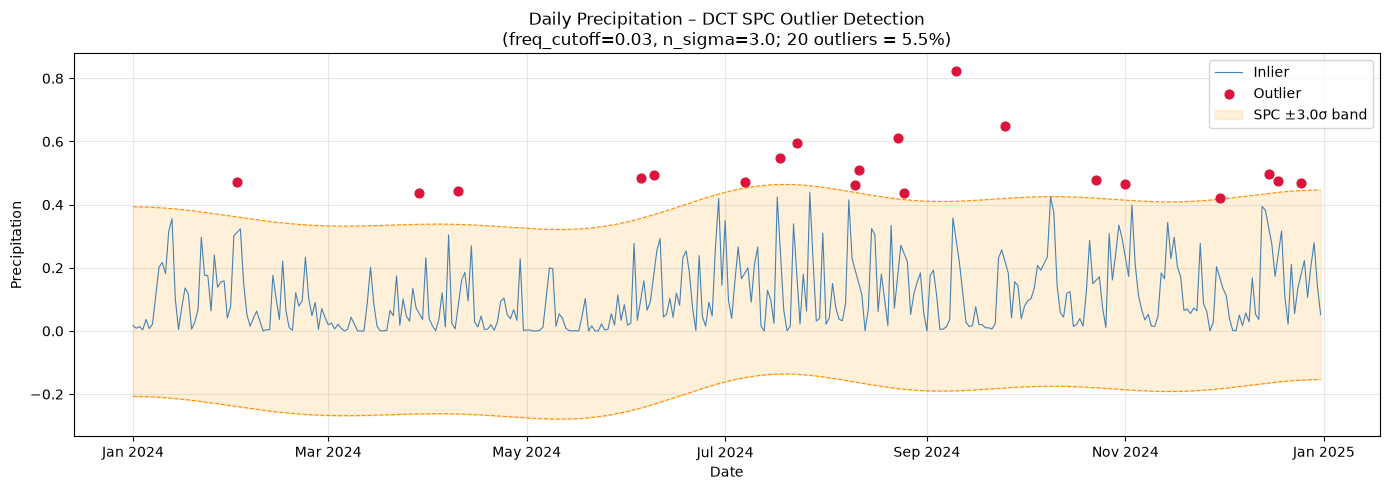


20 precipitation outlier days:


,date,value
32,2024-02-02,0.471196
88,2024-03-29,0.436413
100,2024-04-10,0.442029
156,2024-06-05,0.485870
160,2024-06-09,0.493659
188,2024-07-07,0.472645
199,2024-07-18,0.548460
204,2024-07-23,0.596196
222,2024-08-10,0.461232
223,2024-08-11,0.510236


In [ ]:
def dct_outlier_detection(
    df: pd.DataFrame,
    col: str = 'precipitation',
    freq_cutoff: float = 0.03,
    n_sigma: float = 3.0,
    resample_rule: str = 'D',
) -> tuple[plt.Figure, pd.DataFrame]:
    """Detect outliers in a weather variable using DCT high-pass filtering
    and robust Statistical Process Control (SPC) limits.

    Parameters
    ----------
    df : pd.DataFrame
        Hourly weather DataFrame with a DatetimeIndex (output of
        `download_weather`).
    col : str
        Column to analyse.  Default 'precipitation'.
    freq_cutoff : float
        Fraction of DCT coefficients to zero out (low-frequency cut-off).
        Values between 0.01 and 0.10 are typical.  Default 0.03.
    n_sigma : float
        Number of scaled MAD units from the median that define the SPC
        boundary.  Default 3.0.
    resample_rule : str
        pandas resample rule for temporal aggregation.  Default 'D' (daily).

    Returns
    -------
    fig : plt.Figure
        Figure showing the raw signal with SPC bounds and coloured outliers.
    summary : pd.DataFrame
        Rows corresponding to detected outlier dates.
    """
    # 1. Resample to daily mean and drop NaNs
    series = df[col].resample(resample_rule).mean().dropna()
    values = series.values.astype(float)
    n = len(values)

    # 2. DCT high-pass filter 
    # DCT-II is real-valued and reversible; it is well-suited to time series
    # because it avoids the Gibbs phenomenon at the boundary.
    coeffs = dct(values, norm='ortho')          # forward DCT

    # Zero out everything BELOW the cut-off (the slow seasonal component)
    cutoff_idx = max(1, int(freq_cutoff * n))   # at least 1 coefficient kept
    coeffs_hp = coeffs.copy()
    coeffs_hp[:cutoff_idx] = 0.0               # remove low-frequency baseline

    # Reconstruct: this is the Seasonally Adjusted residual (SATV)
    satv = idct(coeffs_hp, norm='ortho')

    # 3. Robust SPC limits (median + MAD) 
    # MAD scaled to be consistent with the standard deviation for Gaussian data
    median  = np.median(satv)
    mad     = np.median(np.abs(satv - median))
    mad_scaled = mad * 1.4826               # factor makes MAD ≈ σ for Gaussian

    upper = median + n_sigma * mad_scaled
    lower = median - n_sigma * mad_scaled

    # 4. Classify inliers / outliers 
    is_outlier = (satv > upper) | (satv < lower)

    # 5. Build the result DataFrame 
    result_df = pd.DataFrame({
        'date':       series.index,
        'value':      values,
        'satv':       satv,
        'is_outlier': is_outlier,
    })
    summary = result_df[result_df['is_outlier']].copy()

    # 6. Plot 
    fig, ax = plt.subplots(figsize=(14, 5))

    # Raw signal
    inlier_mask = ~is_outlier
    ax.plot(series.index[inlier_mask], values[inlier_mask],
            color='steelblue', linewidth=0.8, label='Inlier', zorder=2)

    # Outliers as red scatter points
    ax.scatter(series.index[is_outlier], values[is_outlier],
               color='crimson', s=40, zorder=4, label='Outlier')

    # SPC boundaries derived from SATV (shift back to original baseline)
    baseline = values - satv          # low-frequency component
    ax.fill_between(
        series.index,
        baseline + lower,
        baseline + upper,
        color='orange', alpha=0.15,
        label=f'SPC ±{n_sigma}σ band'
    )
    ax.plot(series.index, baseline + upper,
            color='darkorange', linewidth=0.8, linestyle='--')
    ax.plot(series.index, baseline + lower,
            color='darkorange', linewidth=0.8, linestyle='--')

    ax.set_title(
        f'Daily {col.replace("_"," ").title()} – DCT SPC Outlier Detection\n'
        f'(freq_cutoff={freq_cutoff}, n_sigma={n_sigma}; '
        f'{is_outlier.sum()} outliers = '
        f'{100*is_outlier.mean():.1f}%)',
        fontsize=12
    )
    ax.set_xlabel('Date')
    ax.set_ylabel(col.replace('_', ' ').title())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.tight_layout()

    return fig, summary


# Test with NO3 2024 precipitation 
fig_dct, outliers_precip = dct_outlier_detection(
    df_weather_no3,
    col='precipitation',
    freq_cutoff=0.03,    # cut off the lowest 3% of DCT coefficients
    n_sigma=3.0,
)
plt.show()

print(f'\n{len(outliers_precip)} precipitation outlier days:')
display(outliers_precip[['date', 'value']].head(10))

## Cell 6 – Temperature anomaly detection using Local Outlier Factor (LOF)

LOF compares the local density of a sample to the densities of its neighbours.
Points in sparse neighbourhoods receive a high LOF score and are flagged as anomalies.
Here we apply it to the daily-mean temperature time series, treating each day as a
1-D point.

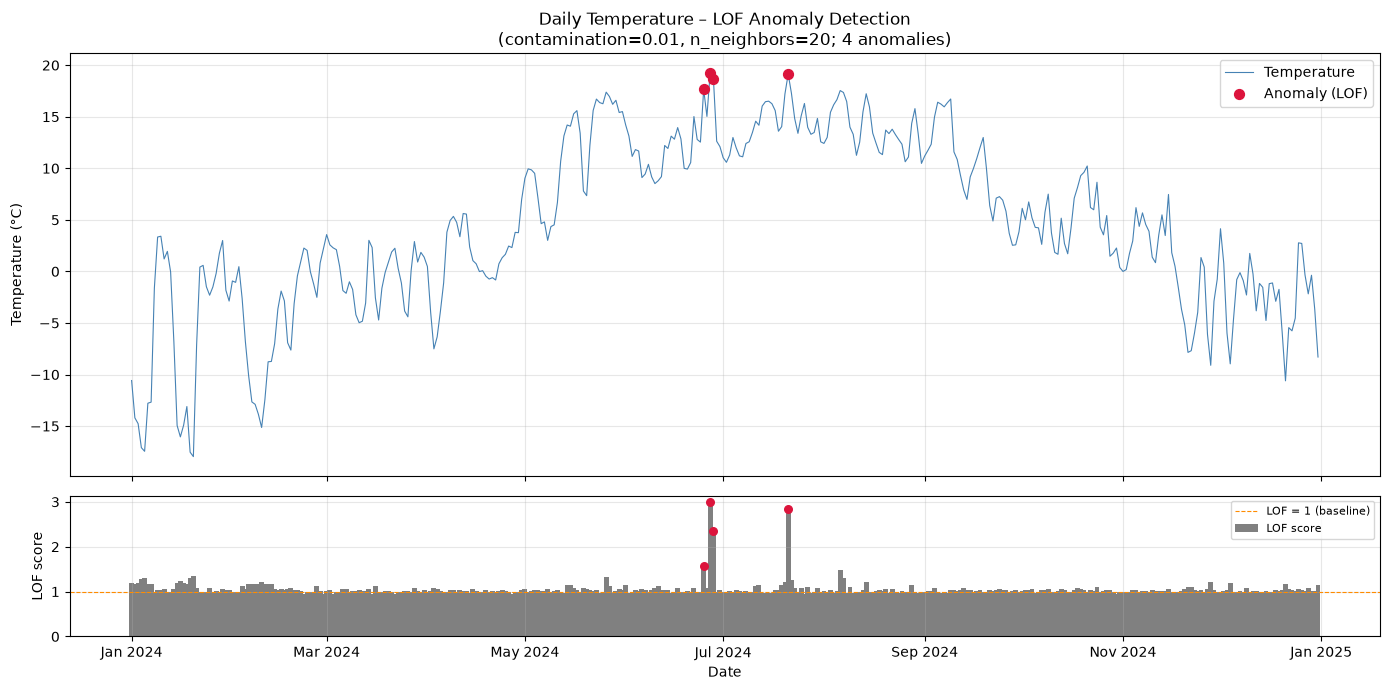


4 temperature anomaly days:


,date,temperature,lof_score
176,2024-06-25,17.655707,1.564462
178,2024-06-27,19.285598,2.988145
179,2024-06-28,18.667482,2.360737
202,2024-07-21,19.147554,2.840599


In [ ]:
def lof_anomaly_detection(
    df: pd.DataFrame,
    col: str = 'temperature_2m',
    contamination: float = 0.01,
    n_neighbors: int = 20,
    resample_rule: str = 'D',
) -> tuple[plt.Figure, pd.DataFrame]:
    """Detect temperature anomalies using the Local Outlier Factor algorithm.

    Parameters
    ----------
    df : pd.DataFrame
        Hourly weather DataFrame with a DatetimeIndex.
    col : str
        Column to analyse.  Default 'temperature_2m'.
    contamination : float
        Expected proportion of anomalies in the dataset (0–0.5).
        Default 0.01 (1%).
    n_neighbors : int
        Number of neighbours for the LOF algorithm.  Default 20.
    resample_rule : str
        pandas resample rule.  Default 'D' (daily).

    Returns
    -------
    fig : plt.Figure
    summary : pd.DataFrame
        Rows corresponding to detected anomaly dates.
    """
    # 1. Resample 
    series = df[col].resample(resample_rule).mean().dropna()
    values = series.values.reshape(-1, 1)   # LOF expects a 2-D array

    # 2. Fit LOF 
    lof = LocalOutlierFactor(
        n_neighbors=n_neighbors,
        contamination=contamination,
        novelty=False,
    )
    # fit_predict returns +1 (inlier) or -1 (anomaly)
    labels     = lof.fit_predict(values)
    lof_scores = -lof.negative_outlier_factor_   # higher = more anomalous
    is_anomaly = labels == -1

    # 3. Build result DataFrame 
    result_df = pd.DataFrame({
        'date':       series.index,
        'temperature': series.values,
        'lof_score':  lof_scores,
        'is_anomaly': is_anomaly,
    })
    summary = result_df[result_df['is_anomaly']].copy()

    # 4. Plot 
    fig, (ax_main, ax_lof) = plt.subplots(
        2, 1, figsize=(14, 7),
        gridspec_kw={'height_ratios': [3, 1]},
        sharex=True,
    )

    # Top panel: temperature with anomalies highlighted
    ax_main.plot(series.index, series.values,
                 color='steelblue', linewidth=0.8, label='Temperature')
    ax_main.scatter(
        series.index[is_anomaly], series.values[is_anomaly],
        color='crimson', s=50, zorder=4, label='Anomaly (LOF)'
    )
    ax_main.set_ylabel('Temperature (°C)')
    ax_main.set_title(
        f'Daily Temperature – LOF Anomaly Detection\n'
        f'(contamination={contamination}, n_neighbors={n_neighbors}; '
        f'{is_anomaly.sum()} anomalies)',
        fontsize=12
    )
    ax_main.legend()
    ax_main.grid(True, alpha=0.3)

    # Bottom panel: LOF scores
    ax_lof.bar(series.index, lof_scores, color='grey', width=1.5, label='LOF score')
    ax_lof.scatter(series.index[is_anomaly], lof_scores[is_anomaly],
                   color='crimson', s=30, zorder=4)
    ax_lof.axhline(1.0, color='darkorange', linestyle='--', linewidth=0.8,
                   label='LOF = 1 (baseline)')
    ax_lof.set_ylabel('LOF score')
    ax_lof.set_xlabel('Date')
    ax_lof.legend(fontsize=8)
    ax_lof.grid(True, alpha=0.3)
    ax_lof.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))

    plt.tight_layout()
    return fig, summary


# Test with NO3 2024 temperature 
fig_lof, anomalies_temp = lof_anomaly_detection(
    df_weather_no3,
    col='temperature_2m',
    contamination=0.01,    # 1% of days expected to be anomalous
    n_neighbors=20,
)
plt.show()

print(f'\n{len(anomalies_temp)} temperature anomaly days:')
display(anomalies_temp[['date', 'temperature', 'lof_score']].head(10))

## Cell 7 – STL decomposition of reservoir fill-percentage

Seasonal-Trend decomposition using LOESS (STL) separates a time series into:
- **Trend** – the long-run movement
- **Seasonal** – the repeating within-year pattern
- **Residual** – everything left over (noise + irregular fluctuations)

The NVE fill-percentage is measured weekly, so `period=52`.

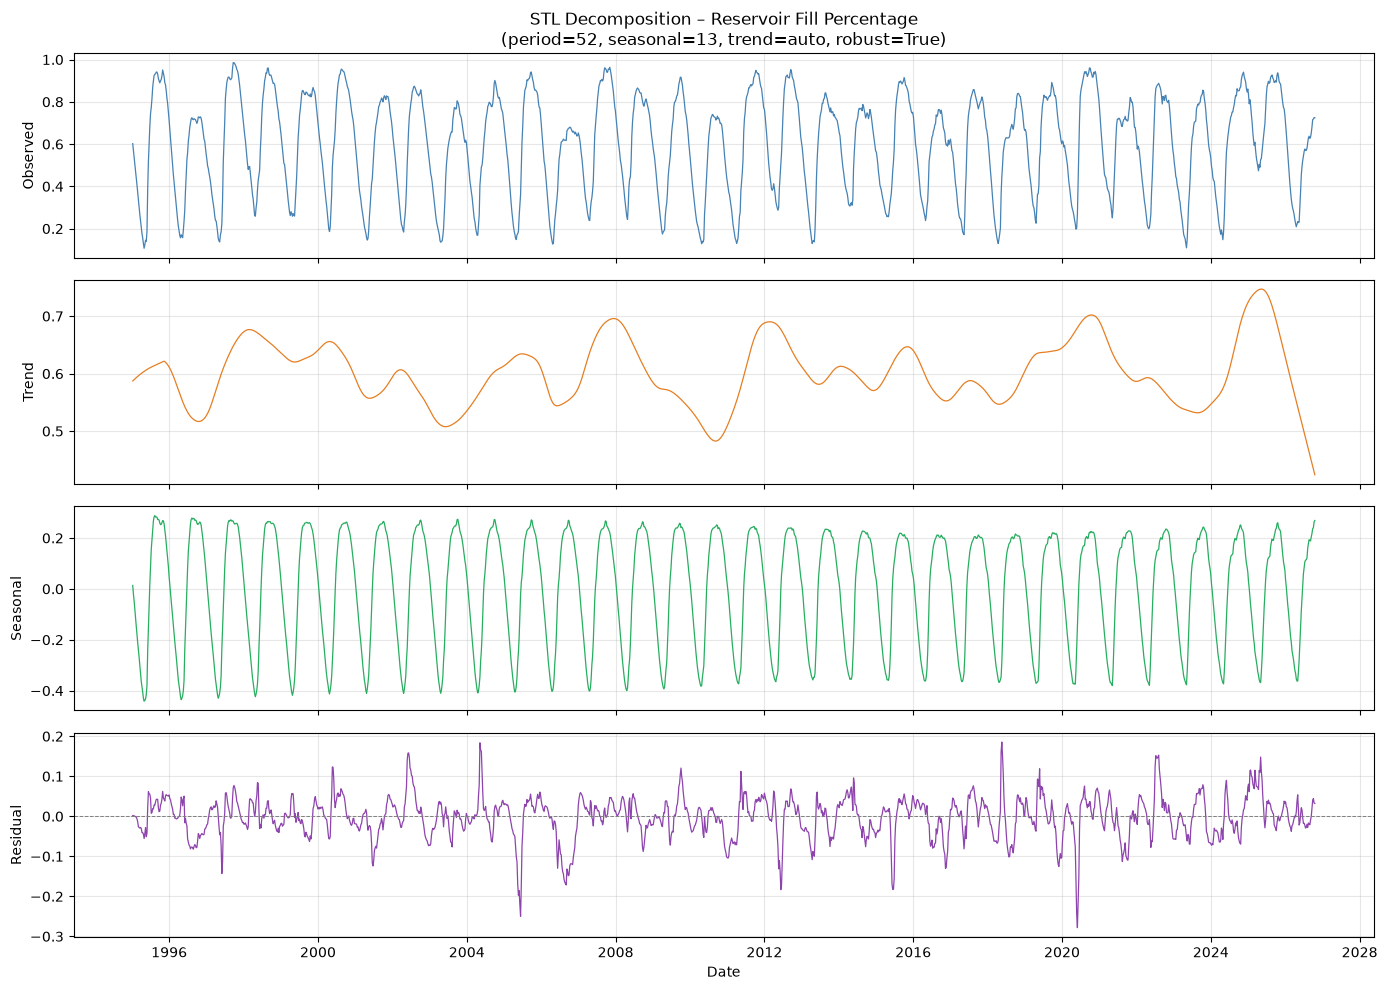

STL components:
  Seasonal  std: 0.224
  Trend     std: 0.055
  Residual  std: 0.052


In [ ]:
def stl_decomposition(
    series: pd.Series,
    period: int = 52,
    seasonal: int = 13,
    trend: int | None = None,
    robust: bool = True,
) -> tuple[plt.Figure, object]:
    """Perform STL decomposition on a time series and plot the result.

    Parameters
    ----------
    series : pd.Series
        Time series with a DatetimeIndex.
    period : int
        Number of observations per season.  Default 52 (weekly NVE data).
    seasonal : int
        Seasonal smoother length (must be odd).  Default 13 (≈ 3 months).
    trend : int or None
        Trend smoother length (must be odd and > period).  None lets
        statsmodels choose automatically (≈ 1.5 × period, rounded up to odd).
    robust : bool
        If True, use robust weighting (resistant to outliers).  Default True.

    Returns
    -------
    fig : plt.Figure
    result : statsmodels DecomposeResult
        Use `result.seasonal`, `result.trend`, `result.resid` for further
        analysis.
    """
    clean = series.dropna()

    # Ensure the seasonal smoother is an odd integer
    if seasonal % 2 == 0:
        seasonal += 1

    stl = STL(
        clean,
        period=period,
        seasonal=seasonal,
        trend=trend,
        robust=robust,
    )
    result = stl.fit()

    # Plot 
    fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)
    components = [
        (clean,            'Observed',  'steelblue'),
        (result.trend,     'Trend',     '#e67e22'),
        (result.seasonal,  'Seasonal',  '#27ae60'),
        (result.resid,     'Residual',  '#8e44ad'),
    ]
    for ax, (data, label, color) in zip(axes, components):
        ax.plot(clean.index, data, color=color, linewidth=0.9)
        ax.set_ylabel(label, fontsize=10)
        ax.grid(True, alpha=0.3)
        if label == 'Residual':
            ax.axhline(0, color='grey', linewidth=0.7, linestyle='--')

    axes[0].set_title(
        f'STL Decomposition – Reservoir Fill Percentage\n'
        f'(period={period}, seasonal={seasonal}, '
        f'trend={trend if trend else "auto"}, robust={robust})',
        fontsize=12
    )
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    axes[-1].set_xlabel('Date')
    plt.tight_layout()

    return fig, result


# Apply STL to NO3 fill_percentage 
# Resample to weekly frequency (NVE publishes weekly) and set fill for dates
fill_series = (
    df_no3.set_index('date')['fill_percentage']
    .resample('W').mean()
    .interpolate(method='linear')  # fill any gaps before STL
)

fig_stl, stl_result = stl_decomposition(
    fill_series,
    period=52,      # 52 weeks per year
    seasonal=13,    # seasonal window ≈ quarter-year
    trend=None,     # auto
    robust=True,
)
plt.show()

print('STL components:')
print(f'  Seasonal  std: {stl_result.seasonal.std():.3f}')
print(f'  Trend     std: {stl_result.trend.std():.3f}')
print(f'  Residual  std: {stl_result.resid.std():.3f}')

## Cell 8 – Spectrogram of reservoir fill-percentage

A spectrogram shows how the power spectrum of the signal changes over time
(Short-Time Fourier Transform, STFT).  Horizontal bands correspond to seasonal
periodicities; strong colours indicate large amplitude at that frequency/time.

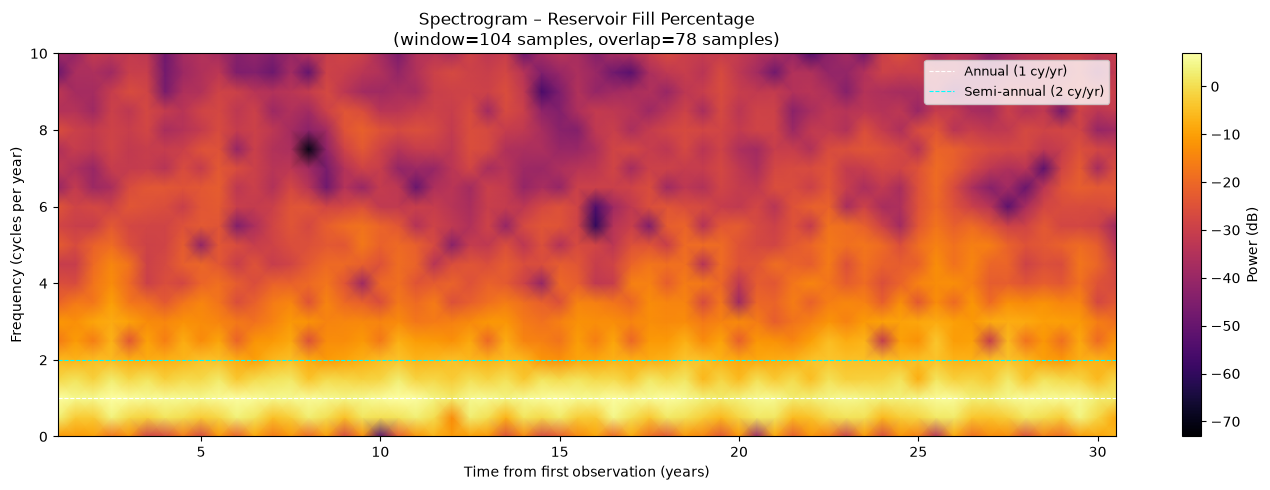

In [8]:
def plot_spectrogram(
    series: pd.Series,
    fs: float = 1.0,
    window_length: int = 104,
    overlap: int = 78,
    cmap: str = 'inferno',
) -> plt.Figure:
    """Create a power spectrogram of a regularly sampled time series.

    Parameters
    ----------
    series : pd.Series
        Time series with a uniform DatetimeIndex.
    fs : float
        Sampling frequency in samples-per-year.  Default 1.0 for weekly data
        (so frequency axis is in cycles-per-sample; multiply by 52 for
        cycles-per-year).
    window_length : int
        Length of each STFT window in samples.  Default 104 (≈ 2 years of
        weekly data).
    overlap : int
        Number of samples shared between consecutive windows.  Default 78
        (75% overlap).
    cmap : str
        Matplotlib colormap for the spectrogram.  Default 'inferno'.

    Returns
    -------
    fig : plt.Figure
    """
    clean = series.dropna().values.astype(float)

    # scipy.signal.spectrogram uses a Hann window by default
    f, t_seg, Sxx = spectrogram(
        clean,
        fs=fs,
        window='hann',
        nperseg=window_length,
        noverlap=overlap,
    )

    # Map segment indices to calendar time
    total_samples = len(clean)
    t_dates = series.dropna().index[
        np.clip((t_seg * total_samples / total_samples).astype(int),
                0, total_samples - 1)
    ]
    # Use numeric positions for the x-axis and label with years
    t_years = t_seg / 52.0     # convert sample-index fractions to years

    fig, ax = plt.subplots(figsize=(14, 5))
    pcm = ax.pcolormesh(
        t_years,
        f * 52,          # cycles per sample → cycles per year
        10 * np.log10(Sxx + 1e-12),   # power in dB
        cmap=cmap,
        shading='gouraud',
    )
    fig.colorbar(pcm, ax=ax, label='Power (dB)')

    # Mark the 1-year and 0.5-year periodicities
    ax.axhline(1.0, color='white', linewidth=0.8, linestyle='--',
               label='Annual (1 cy/yr)')
    ax.axhline(2.0, color='cyan', linewidth=0.8, linestyle='--',
               label='Semi-annual (2 cy/yr)')

    ax.set_xlabel('Time from first observation (years)')
    ax.set_ylabel('Frequency (cycles per year)')
    ax.set_title(
        f'Spectrogram – Reservoir Fill Percentage\n'
        f'(window={window_length} samples, overlap={overlap} samples)',
        fontsize=12
    )
    ax.set_ylim(0, 10)   # show up to 10 cycles per year
    ax.legend(loc='upper right', fontsize=9)
    plt.tight_layout()
    return fig


# ── Test with fill_series (weekly reservoir fill-percentage) ──────────────────
fig_spec = plot_spectrogram(
    fill_series,
    fs=1.0,             # 1 sample per week (frequency axis will be in cy/week)
    window_length=104,  # 2-year window
    overlap=78,         # 75% overlap
)
plt.show()

## Log – Part 3


### AI usage declaration
